# CO4 + CO5 Extension Only — Waste Segregation

This notebook deliberately **does not rerun the completed CO3 CNN experiments or 5-fold cross-validation**. It recreates only the same fixed dataset split and runs the new CO4 benchmark and CO5 ablation experiments. Model checkpoints, CSV files, and figures are saved to Google Drive, so a disconnect does not repeat completed extension experiments.

## Step 1 — Imports and Reproducibility

In [1]:
import os, gc, random, time, json, platform
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve

SEED=42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style='whitegrid')
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 2 — Download Dataset and Recreate the Identical Stratified Split
The Kaggle dataset is downloaded afresh to the Colab runtime. With the same source data and seed 42, this recreates the same 70/15/15 split used in CO3.

In [2]:
!wget -q --show-progress https://www.kaggle.com/api/v1/datasets/download/sujaykapadnis/cnn-waste-classification-image-dataset -O waste_dataset.zip
!unzip -q -o waste_dataset.zip -d /content/waste_data

root=Path('/content/waste_data'); exts={'.jpg','.jpeg','.png','.bmp','.gif','.webp'}
class_dirs=sorted([p for p in root.iterdir() if p.is_dir()])
class_names=[p.name for p in class_dirs]
if set(class_names) != {'organic','recyclable'}:
    raise ValueError(f'Expected organic/recyclable folders, found: {class_names}')
mapping={name:i for i,name in enumerate(class_names)}
rows=[(str(f),d.name,mapping[d.name]) for d in class_dirs for f in d.rglob('*') if f.is_file() and f.suffix.lower() in exts]
df=pd.DataFrame(rows,columns=['filepath','class','class_id'])
dev_df,test_df=train_test_split(df,test_size=.15,stratify=df.class_id,random_state=SEED)
train_df,val_df=train_test_split(dev_df,test_size=.1765,stratify=dev_df.class_id,random_state=SEED)
print('Classes:',class_names,'| Total:',len(df),'| Train:',len(train_df),'| Validation:',len(val_df),'| Test:',len(test_df))

waste_dataset.zip   100%[===================>] 212.38M  20.4MB/s    in 13s     
Classes: ['organic', 'recyclable'] | Total: 24705 | Train: 17292 | Validation: 3707 | Test: 3706


## Step 3 — Data Pipeline
This uses the same 128x128 normalization and training-only augmentation as the completed CO3 experiment.

In [3]:
IMG_SIZE=(128,128); BATCH_SIZE=32; AUTO=tf.data.AUTOTUNE
def decode(path,label):
    image=tf.io.decode_image(tf.io.read_file(path),channels=3,expand_animations=False)
    image.set_shape([None,None,3])
    return tf.cast(tf.image.resize(image,IMG_SIZE),tf.float32)/255.,label
def make_ds(frame,training=False):
    data=tf.data.Dataset.from_tensor_slices((frame.filepath.to_numpy(),frame.class_id.to_numpy(np.int32)))
    if training: data=data.shuffle(len(frame),seed=SEED,reshuffle_each_iteration=True)
    return data.map(decode,num_parallel_calls=AUTO).batch(BATCH_SIZE).prefetch(AUTO)
train_ds,val_ds,test_ds=make_ds(train_df,True),make_ds(val_df),make_ds(test_df)
aug=keras.Sequential([layers.RandomFlip('horizontal'),layers.RandomRotation(.15),layers.RandomZoom(.15),layers.RandomContrast(.10)],name='moderate_augmentation')
counts=train_df.class_id.value_counts(); imbalanced=counts.max()/counts.min()>=1.5
cw=None if not imbalanced else {int(i):float(v) for i,v in enumerate(compute_class_weight('balanced',classes=np.arange(2),y=train_df.class_id))}
print('Class weights:',cw if cw else 'not required; training split is balanced')

Class weights: not required; training split is balanced


# CO4 and CO5 Extension — Comparative Analysis and Innovation

Run this extension only after the preceding CO3 cells have completed. It adds reproducible, checkpointed experiments without changing the frozen train/validation/test split. **No test result is used to choose a model.**

## 35. Reproducibility and Checkpoint Storage
This cell uses Google Drive only to preserve models, tables, figures, and environment versions if Colab disconnects. If a model checkpoint exists, the corresponding experiment is loaded rather than trained again.

In [5]:
from google.colab import drive
from pathlib import Path
import time, json, platform
from sklearn.metrics import roc_auc_score, roc_curve

drive.mount('/content/drive', force_remount=False)
ARTIFACT_DIR = Path('/content/drive/MyDrive/waste_cnn_2430010407_artifacts')
MODEL_DIR, RESULT_DIR, FIGURE_DIR = ARTIFACT_DIR/'models', ARTIFACT_DIR/'results', ARTIFACT_DIR/'figures'
for folder in (MODEL_DIR, RESULT_DIR, FIGURE_DIR): folder.mkdir(parents=True, exist_ok=True)

versions = {
    'python': platform.python_version(), 'tensorflow': tf.__version__, 'numpy': np.__version__,
    'pandas': pd.__version__, 'scikit-learn': __import__('sklearn').__version__,
    'matplotlib': __import__('matplotlib').__version__, 'seaborn': sns.__version__,
    'Pillow': __import__('PIL').__version__
}
pd.DataFrame(versions.items(), columns=['package', 'version']).to_csv(RESULT_DIR/'environment_versions.csv', index=False)
print('Artifacts will be saved to:', ARTIFACT_DIR)
display(pd.DataFrame(versions.items(), columns=['Package', 'Version']))

Mounted at /content/drive
Artifacts will be saved to: /content/drive/MyDrive/waste_cnn_2430010407_artifacts


,Package,Version
0,python,3.13.15
1,tensorflow,2.20.0
2,numpy,2.1.3
3,pandas,2.2.3
4,scikit-learn,1.6.1
5,matplotlib,3.10.0
6,seaborn,0.13.2
7,Pillow,11.3.0


## 36. Additional Binary Metrics: Specificity and ROC-AUC
Specificity measures the proportion of negative-class samples (Organic) that are correctly identified as Organic. Recall measures the proportion of positive-class samples (Recyclable) that are correctly identified as Recyclable. Positive class = Recyclable (class 1). ROC-AUC summarizes the discrimination of the two predicted probability distributions.


In [6]:
def binary_metrics(y_true, probabilities, model_name, parameter_count, train_seconds):
    predicted = (probabilities >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, predicted),
        'Precision': precision_score(y_true, predicted, zero_division=0),
        'Recall': recall_score(y_true, predicted, zero_division=0),
        'F1': f1_score(y_true, predicted, zero_division=0),
        'Specificity': tn / (tn + fp) if tn + fp else np.nan,
        'ROC-AUC': roc_auc_score(y_true, probabilities),
        'Parameters': int(parameter_count),
        'Training Time (s)': train_seconds
    }

def probability_predictions(model):
    probabilities = model.predict(test_ds, verbose=0)
    return probabilities[:, 1] if probabilities.ndim == 2 else probabilities.reshape(-1)

print('Positive class:', class_names[1], '| Negative class:', class_names[0])

Positive class: recyclable | Negative class: organic


## 37. CO5 Innovation: Regularized Lightweight Feature Aggregation CNN (RLFA-CNN)
The proposed project-level contribution is a parameter-efficient CNN combining: (1) moderate augmentation, (2) Batch Normalization, (3) Global Average Pooling instead of a large Flatten layer, (4) L1 regularization, and (5) adaptive learning-rate reduction. This is not claimed as a universally new neural-network invention; its contribution is tested empirically on this waste dataset through the ablation study below.

In [7]:
def plain_cnn():
    model = models.Sequential([
        layers.Input(shape=(*IMG_SIZE, 3)),
        layers.Conv2D(32, 3, activation='relu', padding='same'), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation='relu', padding='same'), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation='relu', padding='same'), layers.MaxPooling2D(),
        layers.Flatten(), layers.Dense(128, activation='relu'), layers.Dropout(0.3),
        layers.Dense(2, activation='softmax')])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def feature_aggregation_cnn(use_l1=False):
    penalty = regularizers.l1(1e-5) if use_l1 else None
    model = models.Sequential([layers.Input(shape=(*IMG_SIZE, 3)), aug])
    for filters in (32, 64, 128):
        model.add(layers.Conv2D(filters, 3, padding='same', activation='relu', kernel_regularizer=penalty))
        model.add(layers.BatchNormalization())
        model.add(layers.MaxPooling2D())
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dense(128, activation='relu', kernel_regularizer=penalty))
    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(2, activation='softmax'))
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

ABLATION_EPOCHS = 30
def train_or_load(name, builder, epochs=ABLATION_EPOCHS):
    path = MODEL_DIR / f'{name}.keras'
    history_path = RESULT_DIR / f'{name}_history.csv'
    start = time.time()
    if path.exists():
        print(f'Loading checkpoint: {name}')
        model = keras.models.load_model(path)
        history = pd.read_csv(history_path).to_dict(orient='list') if history_path.exists() else {}
        seconds = 0.0
    else:
        tf.keras.backend.clear_session(); gc.collect(); model = builder()
        callbacks = [EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
                     ReduceLROnPlateau(monitor='val_loss', factor=.5, patience=2, min_lr=1e-6)]
        history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks,
                            class_weight=cw, verbose=1).history
        seconds = time.time() - start
        model.save(path)
        pd.DataFrame(history).to_csv(history_path, index=False)
    return model, history, seconds


## 38. CO5 Ablation Study
Every row is a fresh model trained with the same splits. This tests whether the proposed components materially improve validation/test performance, rather than claiming innovation from hyperparameter changes alone.

Epoch 1/30
541/541 ━━━━━━━━━━━━━━━━━━━━ 27s 36ms/step - accuracy: 0.8091 - loss: 0.4456 - val_accuracy: 0.8430 - val_loss: 0.3668 - learning_rate: 0.0010
Epoch 2/30
541/541 ━━━━━━━━━━━━━━━━━━━━ 30s 26ms/step - accuracy: 0.8415 - loss: 0.3780 - val_accuracy: 0.8465 - val_loss: 0.3803 - learning_rate: 0.0010
Epoch 3/30
541/541 ━━━━━━━━━━━━━━━━━━━━ 21s 26ms/step - accuracy: 0.8581 - loss: 0.3443 - val_accuracy: 0.8603 - val_loss: 0.3307 - learning_rate: 0.0010
Epoch 4/30
541/541 ━━━━━━━━━━━━━━━━━━━━ 19s 24ms/step - accuracy: 0.8731 - loss: 0.3137 - val_accuracy: 0.8716 - val_loss: 0.3211 - learning_rate: 0.0010
Epoch 5/30
541/541 ━━━━━━━━━━━━━━━━━━━━ 21s 25ms/step - accuracy: 0.8823 - loss: 0.2885 - val_accuracy: 0.8713 - val_loss: 0.3157 - learning_rate: 0.0010
Epoch 6/30
541/541 ━━━━━━━━━━━━━━━━━━━━ 13s 25ms/step - accuracy: 0.8995 - loss: 0.2489 - val_accuracy: 0.8689 - val_loss: 0.3259 - learning_rate: 0.0010
Epoch 7/30
541/541 ━━━━━━━━━━━━━━━━━━━━ 21s 26ms/step - accuracy: 0.9171 - l

,Model,Accuracy,Precision,Recall,F1,Specificity,ROC-AUC,Parameters,Training Time (s),Augmentation,BatchNorm + GAP,L1,Best Validation Accuracy
0,Ablation_1_SimpleCNN,0.863465,0.851572,0.833744,0.842564,0.886647,0.935153,4287938,211.050105,No,No,No,0.872943
1,Ablation_2_FeatureAggregation,0.890178,0.844759,0.918103,0.879906,0.868396,0.955069,110914,688.089011,Yes,Yes,No,0.900998
2,Ablation_3_Proposed_RLFA_L1,0.890988,0.834430,0.937192,0.882831,0.854947,0.956544,110914,880.439395,Yes,Yes,Yes,0.892905


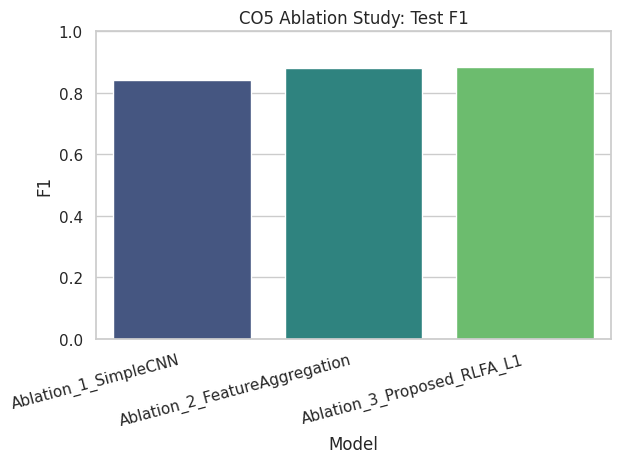

In [8]:
ablation_specs = [
    ('Ablation_1_SimpleCNN', plain_cnn, 'No', 'No', 'No'),
    ('Ablation_2_FeatureAggregation', lambda: feature_aggregation_cnn(False), 'Yes', 'Yes', 'No'),
    ('Ablation_3_Proposed_RLFA_L1', lambda: feature_aggregation_cnn(True), 'Yes', 'Yes', 'Yes')]
ablation_rows, ablation_models = [], {}
for name, builder, augmentation_used, aggregation_used, l1_used in ablation_specs:
    model, history, seconds = train_or_load(name, builder)
    probabilities = probability_predictions(model)
    row = binary_metrics(test_df.class_id.to_numpy(), probabilities, name, model.count_params(), seconds)
    row.update({'Augmentation': augmentation_used, 'BatchNorm + GAP': aggregation_used, 'L1': l1_used,
                'Best Validation Accuracy': max(history.get('val_accuracy', [np.nan]))})
    ablation_rows.append(row); ablation_models[name] = model
ablation_df = pd.DataFrame(ablation_rows)
ablation_df.to_csv(RESULT_DIR/'ablation_results.csv', index=False); ablation_df.to_csv(RESULT_DIR/'ablation_study.csv', index=False)
display(ablation_df)
ax = sns.barplot(data=ablation_df, x='Model', y='F1', hue='Model', palette='viridis', legend=False)
plt.title('CO5 Ablation Study: Test F1'); plt.ylim(0, 1); plt.xticks(rotation=15, ha='right')
plt.tight_layout(); plt.savefig(FIGURE_DIR/'ablation_results.png', dpi=200, bbox_inches='tight'); plt.savefig(FIGURE_DIR/'ablation_study.png', dpi=200, bbox_inches='tight'); plt.show()

## 39. CO4 Comparative Analysis: Same Dataset, Same Split
MobileNetV2 and EfficientNetB0 are established pretrained CNN architectures. Both are trained here using the identical train/validation/test split and the same metrics as the proposed model. Their test scores are reported only after training; validation loss controls Early Stopping.

In [9]:
BENCHMARK_EPOCHS = 15
def transfer_model(architecture):
    inputs = layers.Input(shape=(*IMG_SIZE, 3))
    x = aug(inputs)
    if architecture == 'MobileNetV2':
        x = tf.keras.applications.mobilenet_v2.preprocess_input(x * 255.0)
        backbone = tf.keras.applications.MobileNetV2(include_top=False, weights='imagenet', input_shape=(*IMG_SIZE, 3))
    elif architecture == 'EfficientNetB0':
        x = x * 255.0
        backbone = tf.keras.applications.EfficientNetB0(include_top=False, weights='imagenet', input_shape=(*IMG_SIZE, 3))
    else: raise ValueError(architecture)
    backbone.trainable = False
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(.25)(x)
    outputs = layers.Dense(2, activation='softmax')(x)
    model = keras.Model(inputs, outputs, name=architecture)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

sota_rows, sota_models = [], {}
for architecture in ('MobileNetV2', 'EfficientNetB0'):
    model, history, seconds = train_or_load(architecture, lambda a=architecture: transfer_model(a), BENCHMARK_EPOCHS)
    probabilities = probability_predictions(model)
    row = binary_metrics(test_df.class_id.to_numpy(), probabilities, architecture, model.count_params(), seconds)
    row['Best Validation Accuracy'] = max(history.get('val_accuracy', [np.nan]))
    sota_rows.append(row); sota_models[architecture] = model
sota_df = pd.DataFrame(sota_rows)
display(sota_df)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/15
541/541 ━━━━━━━━━━━━━━━━━━━━ 25s 35ms/step - accuracy: 0.8840 - loss: 0.2982 - val_accuracy: 0.9239 - val_loss: 0.1922 - learning_rate: 0.0010
Epoch 2/15
541/541 ━━━━━━━━━━━━━━━━━━━━ 17s 32ms/step - accuracy: 0.9073 - loss: 0.2452 - val_accuracy: 0.9139 - val_loss: 0.2328 - learning_rate: 0.0010
Epoch 3/15
541/541 ━━━━━━━━━━━━━━━━━━━━ 19s 35ms/step - accuracy: 0.9112 - loss: 0.2350 - val_accuracy: 0.9285 - val_loss: 0.1806 - learning_rate: 0.0010
Epoch 4/15
541/541 ━━━━━━━━━━━━━━━━━━━━ 17s 31ms/step - accuracy: 0.9102 - loss: 0.2301 - val_accuracy: 0.9331 - val_loss: 0.1819 - learning_rate: 0.0010
Epoch 5/15
541/541 ━━━━━━━━━━━━━━━━━━━━ 17s 32ms/step - accuracy: 0.9128 - loss: 0.2279 - val_accuracy: 0.9253 - val_loss: 0.1930 - learning_rate: 0.0010
Epoch 6/15
541/541 ━━━━━━━━━━━━━━━━━━━━ 17s 32ms/step - accuracy: 0.9153 - loss: 0.2224 - val_accuracy: 0.9334 - val_loss: 0.1832 - learning_rate: 5.0000e-04
Epoch 7/15
541/541 ━━━━

,Model,Accuracy,Precision,Recall,F1,Specificity,ROC-AUC,Parameters,Training Time (s),Best Validation Accuracy
0,MobileNetV2,0.922018,0.907758,0.915025,0.911377,0.927474,0.975807,2260546,267.606661,0.935527
1,EfficientNetB0,0.930923,0.916565,0.926724,0.921617,0.934198,0.977293,4052133,488.797602,0.936876


## 40. Final CO4 Comparison, ROC Curves, and Export
The proposed RLFA-CNN + L1 configuration from the controlled ablation study is evaluated alongside EfficientNetB0 and MobileNetV2 on the same untouched test set. This table combines the proposed model and transfer-learning benchmarks using the same untouched test set. It exports all tables and figures for the submission ZIP.

,Model,Accuracy,Precision,Recall,F1,Specificity,ROC-AUC,Parameters,Training Time (s),Best Validation Accuracy
1,EfficientNetB0,0.930923,0.916565,0.926724,0.921617,0.934198,0.977293,4052133,488.797602,0.936876
0,MobileNetV2,0.922018,0.907758,0.915025,0.911377,0.927474,0.975807,2260546,267.606661,0.935527
2,Proposed RLFA-CNN + L1,0.890988,0.834430,0.937192,0.882831,0.854947,0.956544,110914,880.439395,0.892905


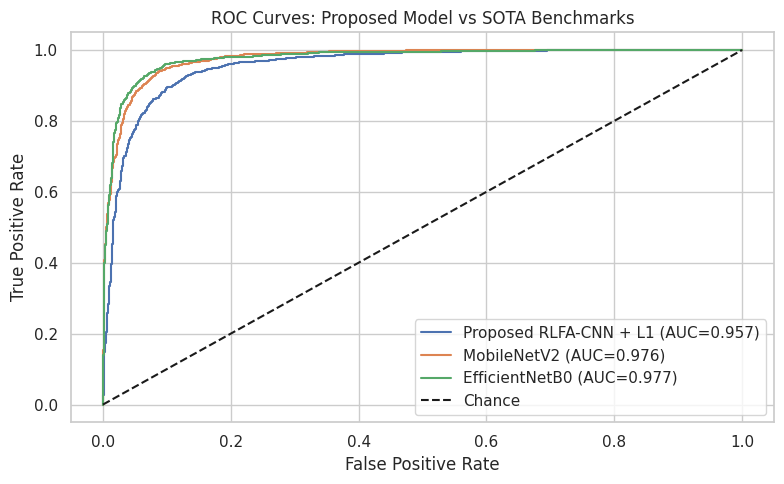

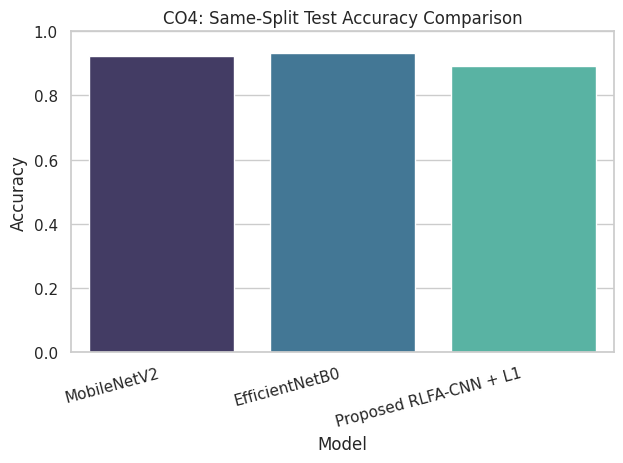

Saved required CO4/CO5 tables and figures to: /content/drive/MyDrive/waste_cnn_2430010407_artifacts
Download that folder from Google Drive after execution and place its files in your submission results/ and figures/ folders.


In [10]:
proposed_row = ablation_df.loc[ablation_df['Model'] == 'Ablation_3_Proposed_RLFA_L1'].copy()
proposed_row['Model'] = 'Proposed RLFA-CNN + L1'
comparison_df = pd.concat([sota_df, proposed_row[sota_df.columns]], ignore_index=True)
comparison_df.to_csv(RESULT_DIR/'sota_comparison.csv', index=False); comparison_df.to_csv(RESULT_DIR/'comparison.csv', index=False)
display(comparison_df.sort_values('Accuracy', ascending=False))

plt.figure(figsize=(8, 5))
models_for_roc = {'Proposed RLFA-CNN + L1': ablation_models['Ablation_3_Proposed_RLFA_L1'], **sota_models}
for name, model in models_for_roc.items():
    probs = probability_predictions(model); fpr, tpr, _ = roc_curve(test_df.class_id, probs)
    plt.plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(test_df.class_id, probs):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Chance'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves: Proposed Model vs Transfer-Learning Benchmarks'); plt.legend(); plt.tight_layout()
plt.savefig(FIGURE_DIR/'roc_curve_sota.png', dpi=200, bbox_inches='tight'); plt.savefig(FIGURE_DIR/'roc_curve.png', dpi=200, bbox_inches='tight'); plt.show()

ax = sns.barplot(data=comparison_df, x='Model', y='Accuracy', hue='Model', palette='mako', legend=False)
plt.ylim(0, 1); plt.title('CO4: Same-Split Test Accuracy Comparison'); plt.xticks(rotation=15, ha='right'); plt.tight_layout()
plt.savefig(FIGURE_DIR/'sota_comparison.png', dpi=200, bbox_inches='tight'); plt.show()

print('Saved required CO4/CO5 tables and figures to:', ARTIFACT_DIR)
print('Download that folder from Google Drive after execution and place its files in your submission results/ and figures/ folders.')

## 41. References for CO4
1. Sandler, M. et al. *MobileNetV2: Inverted Residuals and Linear Bottlenecks.* CVPR, 2018.
2. Tan, M. and Le, Q. *EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks.* ICML, 2019.
3. Nnamoko, N., Barrowclough, J., and Procter, J. *Waste Classification Dataset*, Mendeley Data, Version 3, 2023. The Kaggle Organic/Recyclable copy used in this project is documented in `data/dataset_information.txt`.

## 42. Submission Note
After all extension cells finish, download the Drive artifact folder, replace the placeholder results/figures in the local submission folder, download this executed notebook, and create `2430010407.zip`.